In [1]:
# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# STEP 2: LOAD TRAINING DATA

columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    "../data/raw/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", train_df.shape)
train_df.head()

Dataset shape: (20631, 26)


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
# STEP 3: ANALYZE SENSOR VARIABILITY

sensor_columns = [
    col for col in train_df.columns
    if col.startswith("sensor_")
]

sensor_variability = train_df[sensor_columns].nunique().sort_values()

print("Unique values per sensor:")
print(sensor_variability)

Unique values per sensor:
sensor_1        1
sensor_19       1
sensor_18       1
sensor_5        1
sensor_16       1
sensor_10       1
sensor_6        2
sensor_17      13
sensor_8       53
sensor_13      56
sensor_20     120
sensor_11     159
sensor_2      310
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64


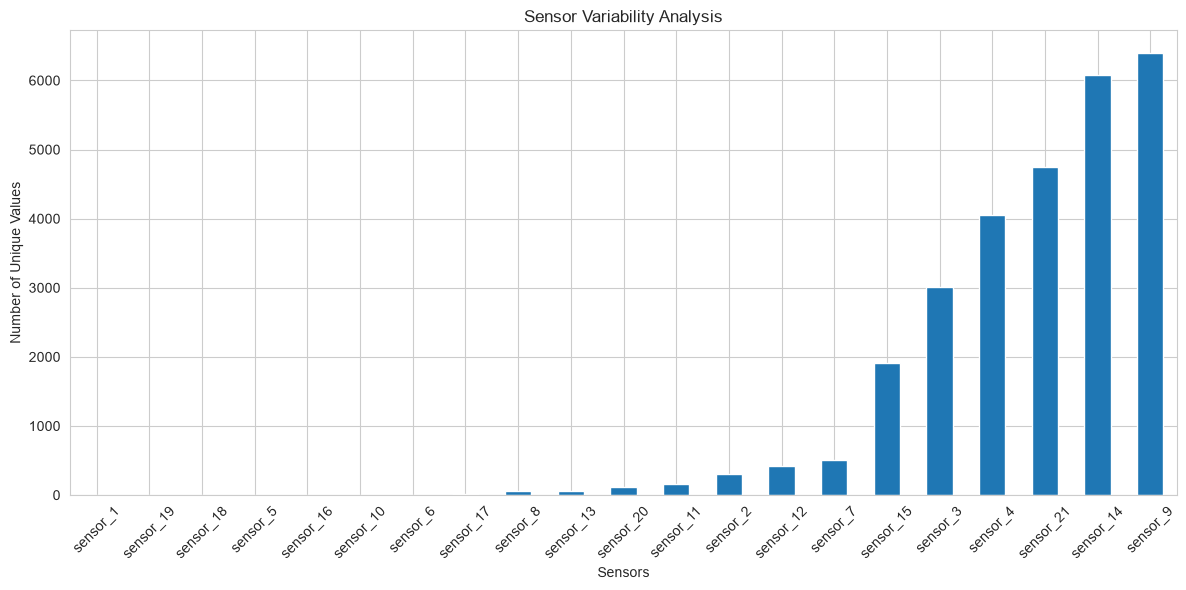

In [4]:
# STEP 4: SENSOR VARIABILITY PLOT

plt.figure(figsize=(12, 6))

sensor_variability.plot(kind="bar")

plt.title("Sensor Variability Analysis")
plt.xlabel("Sensors")
plt.ylabel("Number of Unique Values")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../artifacts/plots/sensor_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
import os
os.makedirs("../artifacts/plots", exist_ok=True)

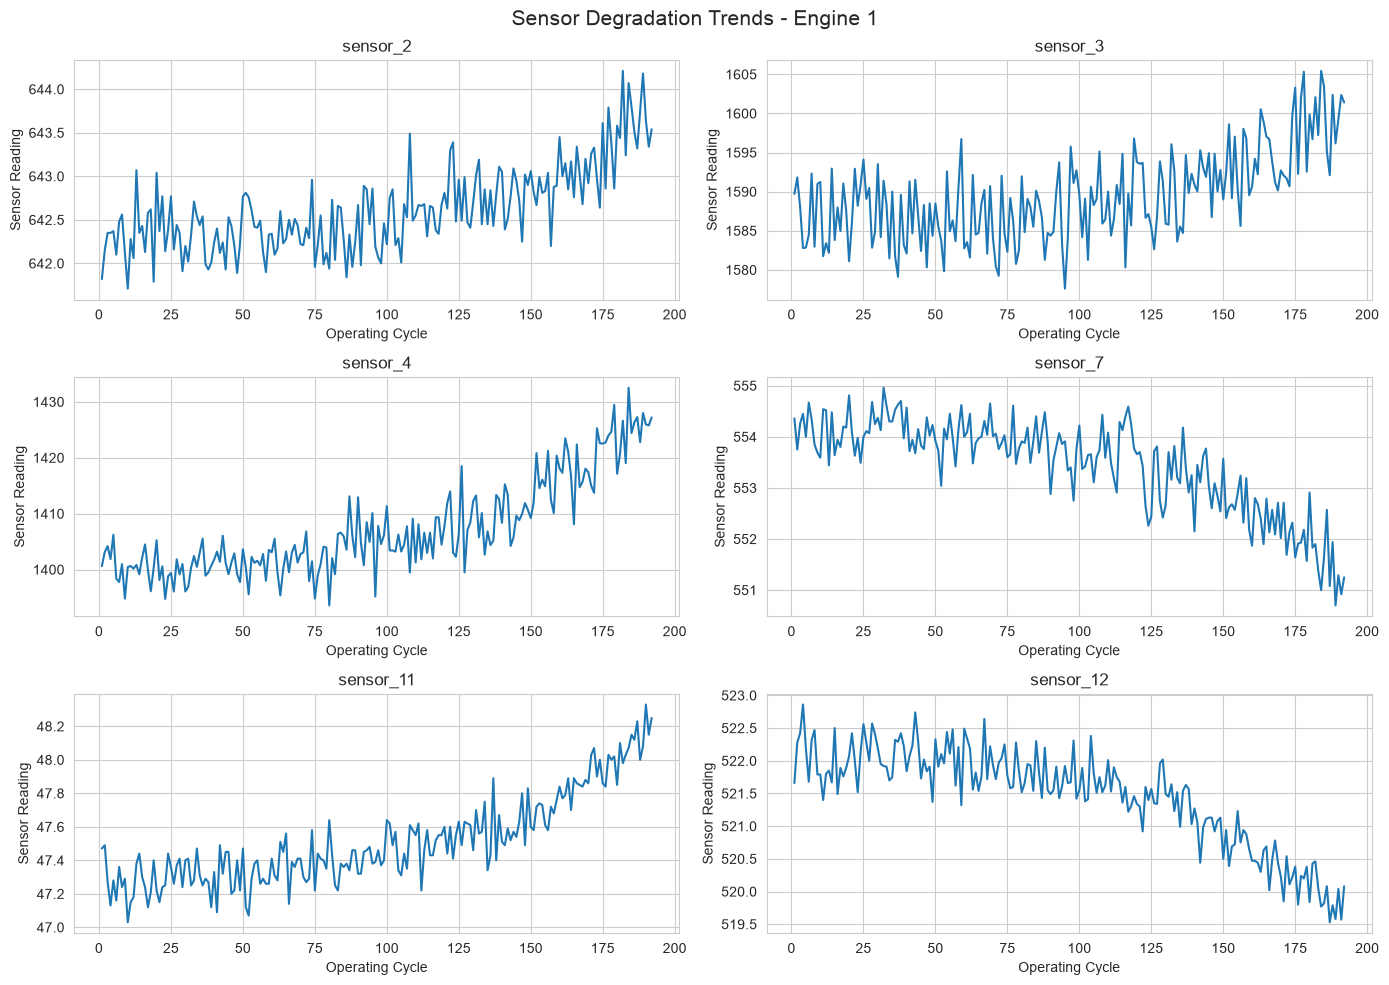

In [6]:
# STEP 6: SENSOR DEGRADATION TRENDS

engine_1 = train_df[train_df["unit"] == 1]

selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for sensor, ax in zip(selected_sensors, axes.flatten()):

    ax.plot(engine_1["cycle"], engine_1[sensor])

    ax.set_title(sensor)
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")

plt.suptitle(
    "Sensor Degradation Trends - Engine 1",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "../artifacts/plots/engine_1_sensor_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

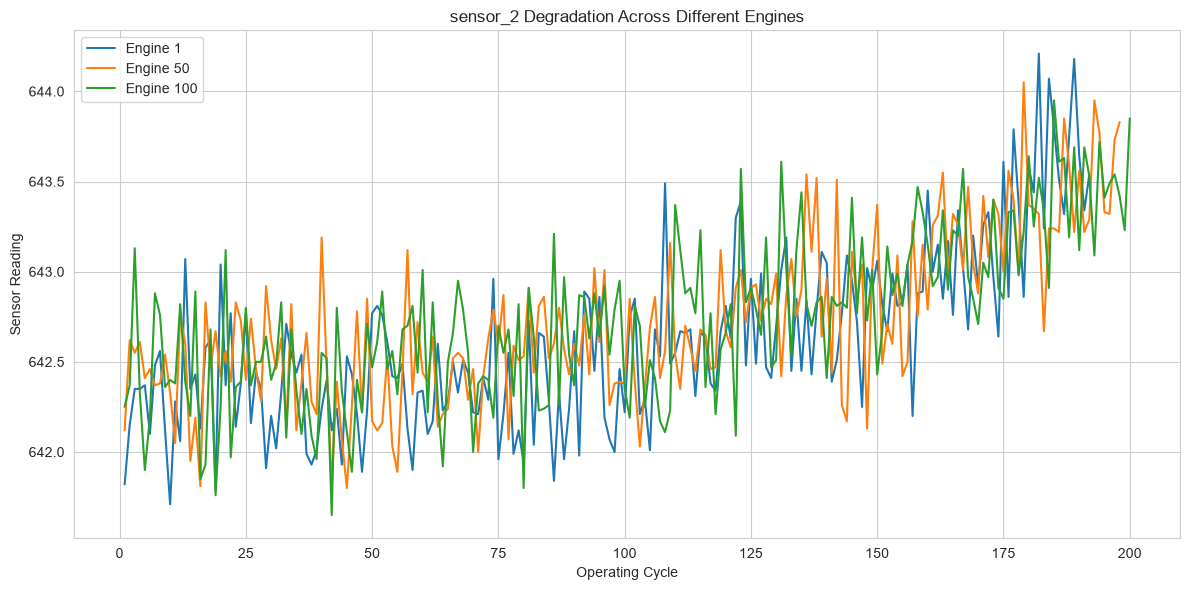

In [7]:
# STEP 7: COMPARE SENSOR TRENDS ACROSS ENGINES

selected_engines = [1, 50, 100]
sensor = "sensor_2"

plt.figure(figsize=(12, 6))

for unit in selected_engines:

    engine_data = train_df[train_df["unit"] == unit]

    plt.plot(
        engine_data["cycle"],
        engine_data[sensor],
        label=f"Engine {unit}"
    )

plt.title(f"{sensor} Degradation Across Different Engines")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Reading")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../artifacts/plots/engine_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

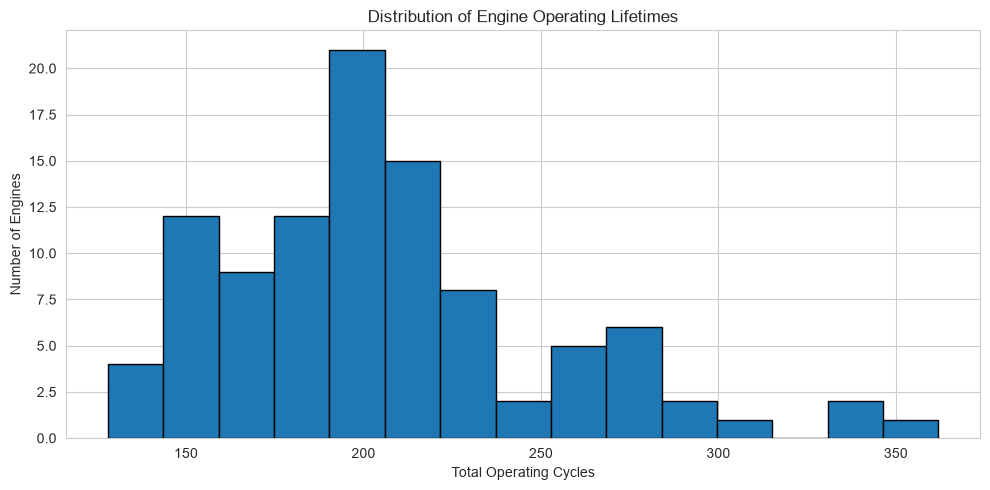

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


In [8]:
# STEP 8: ENGINE LIFETIME DISTRIBUTION

engine_lifetimes = train_df.groupby("unit")["cycle"].max()

plt.figure(figsize=(10, 5))

plt.hist(engine_lifetimes, bins=15, edgecolor="black")

plt.title("Distribution of Engine Operating Lifetimes")
plt.xlabel("Total Operating Cycles")
plt.ylabel("Number of Engines")
plt.tight_layout()

plt.savefig(
    "../artifacts/plots/engine_lifetime_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(engine_lifetimes.describe())

In [10]:
# STEP 9: EDA SUMMARY

constant_sensors = sensor_variability[
    sensor_variability == 1
].index.tolist()

print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("---------------------------------")

print("Total engines:", train_df["unit"].nunique())
print("Total sensors:", len(sensor_columns))

print("Constant sensors:", len(constant_sensors))
print("Variable sensors:", len(sensor_columns) - len(constant_sensors))

print("\nConstant sensor names:")
print(constant_sensors)

print("\nEngine lifetime statistics:")
print(engine_lifetimes.describe())

EXPLORATORY DATA ANALYSIS SUMMARY
---------------------------------
Total engines: 100
Total sensors: 21
Constant sensors: 6
Variable sensors: 15

Constant sensor names:
['sensor_1', 'sensor_19', 'sensor_18', 'sensor_5', 'sensor_16', 'sensor_10']

Engine lifetime statistics:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64
